# Домашнее задание. Применение статистических критериев

В этом задании вы потренируетесь подбирать и применять статистические критерии под конкретную задачу: доверительные интервалы, одновыборочные и двухвыборочные тесты, дисперсионный анализ и анализ долей.

Инструкции:
- Скопируйте ноутбук себе и заполните ячейки с кодом и выводами.
- В каждой задаче приведите код, выведите на экран требуемые значения и добавьте краткий вывод (1-2 фразы) в текстовой ячейке.
- Там, где используется случайная генерация, фиксируйте np.random.seed для воспроизводимости.
- Разрешённые библиотеки: numpy, scipy, statsmodels, matplotlib.

Формат сдачи: файл .ipynb с заполненными ячейками. Перед отправкой перезапустите ноутбук от начала до конца, чтобы **вывод от кода был отображён**.

In [1]:
# ячейка с импортами - дополняйте по своему желанию
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import f, f_oneway, levene, norm, shapiro, t, ttest_ind, ttest_rel
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

### Задание 1. Сопоставление статистик

Для каждой ситуации укажите наиболее подходящий критерий из списка: z-тест, t-тест (объединённый), Welch t-тест, F-тест (сравнение дисперсий), критерий хи-квадрат (согласия), однофакторный ANOVA, Tukey HSD, критерий Левена.

**Ситуации:**
1. Нужно проверить, отличается ли средний объём дозы от заданного значения; дисперсия процесса известна.
2. Сравнить средние двух независимых групп при неизвестных, но равных дисперсиях.
3. Сравнить средние двух независимых групп при неизвестных и неравных дисперсиях.
4. Оценить, одинаковы ли средние в трёх и более группах.
5. Проверить, согласуются ли наблюдаемые частоты с распределением Пуассона.

**Что сделать:** для каждой ситуации кратко (1-2 предложения) обоснуйте выбор критерия в MarkDown-ячейке ниже.

**Вывод:**

1. Так как дисперсия известна, то для анализа берем z-тест: он позволяет использовать известную дисперсию для расчета стандартной ошибки среднего.
2. Используем объединенный t-тест: так как дисперсии равны, оцениваем общую дисперсию по двум выборкам. Распределение Стьюдента имеет более тяжелые хвосты, что позволяет учитывать неопределенность, связанную с неизвестной дисперсией.
3. Welch t-тест — статистика Уэлча используется для того, чтобы учитывать влияние различных дисперсий на результат анализа.
4. Используем ANOVA — определит, есть ли существенные различия по среднему хотя бы между двумя группами. При статистически значимом результате можем использовать Tukey HSD тест, чтобы понять, между какими именно группами есть различия.
5. Хи-квадрат — сравнивает наблюдаемые частоты с ожидаемыми по распределению Пуассона и позволяет проверить, согласуются ли данные с этим распределением.

### Задание 2. Тест для дозатора

Дозатор настроен на среднюю дозу 3.00 г. Получено $n = 50$ измерений со средним $\bar X = 3.005$ и известным стандартным отклонением процесса $\sigma = 0.015$.

**Что сделать:**
- проверьте гипотезу $H_0: \mu = 3.00$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для $\mu$;
- сделайте практический вывод в MarkDown-ячейке: нужно ли перенастраивать дозатор.

**Выведите на экран:** наблюдаемое значение статистики, p-value, границы доверительного интервала.

In [2]:
mu0, xbar, sigma, n = 3.00, 3.005, 0.015, 50

alpha = 0.05

# Проверяем, отличается ли средняя доза от настройки: 
# гипотезы - H0: μ = 3.00, H1: μ <> 3.00.
se = sigma / np.sqrt(n)
z = (xbar - mu0) / se
# Берем двустороннее отклонение: проверяем и недолив, и перелив, поэтому учитываем оба хвоста распределения.
p_value = 2 * norm.sf(abs(z))

# Оцениваем диапазон значений средней дозы, согласующихся с измерениями.
z_critical = norm.ppf(1 - alpha / 2)
ci_lower = xbar - z_critical * se
ci_upper = xbar + z_critical * se

print(f"z-статистика: {z:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% доверительный интервал: [{ci_lower:.5f}, {ci_upper:.5f}]")

z-статистика: 2.3570
p-value: 0.0184
95% доверительный интервал: [3.00084, 3.00916]


**Вывод:** Так как полученный 95% доверительный интервал [3,00084; 3,00916] г не содержит значение 3,00 г и целиком лежит выше него, делаем вывод, что дозатор систематически завышает среднюю дозу, поэтому рекомендуется перенастроить дозатор на заданные 3,00 г. При многократном повторении эксперимента интервалы, построенные таким способом, содержали бы истинную среднюю дозу примерно в 95 случаях из 100.

### Задание 3. Сравнение прочности материалов

Даны две независимые выборки прочности материалов (в MPa):

A (n=15): 51.99, 49.45, 52.59, 56.09, 49.06, 49.06, 56.32, 53.07, 48.12, 52.17, 48.15, 48.14, 50.97, 42.35, 43.10

B (n=10): 48.63, 45.92, 53.89, 46.55, 43.53, 60.79, 50.65, 52.41, 43.45, 48.73

**Что сделать:**
- проверьте равенство дисперсий (критерий Левена и классический F-тест);
- в зависимости от результата примените объединённый t-тест или Welch t-тест для проверки $H_0: \mu_A = \mu_B$ при $\alpha = 0.05$;
- постройте 95% доверительный интервал для разности средних и интерпретируйте его.

Выведите на экран: p-value критерия Левена, F-статистику и p-value F-теста, статистику и p-value выбранного t-теста, разность средних и границы доверительного интервала.

In [3]:
A = np.array([51.99,49.45,52.59,56.09,49.06,49.06,56.32,53.07,48.12,52.17,48.15,48.14,50.97,42.35,43.10])
B = np.array([48.63,45.92,53.89,46.55,43.53,60.79,50.65,52.41,43.45,48.73])

alpha = 0.05
n_a, n_b = len(A), len(B)
var_a, var_b = np.var(A, ddof=1), np.var(B, ddof=1)

# Проверяем, одинаков ли разброс прочности материалов: H0: σ²_A = σ²_B.
# Для классического F-теста предполагаем нормальность в обеих группах.
_, p_levene = levene(A, B, center="median")
f_stat = var_a / var_b

# Проверка двусторонняя: дисперсия A может быть как больше, так и меньше дисперсии B.
p_f = 2 * min(f.cdf(f_stat, n_a - 1, n_b - 1), f.sf(f_stat, n_a - 1, n_b - 1))
print("p-value критерия Левена:", round(p_levene, 4))
print("F-статистика:", round(f_stat, 4))
print("p-value F-теста:", round(p_f, 4))

p-value критерия Левена: 0.5009
F-статистика: 0.5656
p-value F-теста: 0.3271


Так как p-value критерия Левена = 0,5009 и F-теста = 0,3271 больше 0,05, то нет оснований отвергать гипотезу о равенстве дисперсий.
Поэтому для сравнения средних используем объединенный t-тест.

In [4]:
# Проверяем различие средних в обе стороны: H0: μ_A = μ_B, H1: μ_A <> μ_B.
t_stat, p_value = ttest_ind(A, B, equal_var=True, alternative="two-sided")

# Строим доверительный интервал, который покажет, какие значения средних согласуются с данными.
mean_diff = np.mean(A) - np.mean(B)
df = n_a + n_b - 2
pooled_var = ((n_a - 1) * var_a + (n_b - 1) * var_b) / df
se = np.sqrt(pooled_var * (1 / n_a + 1 / n_b))
t_critical = t.ppf(1 - alpha / 2, df)
ci_lower = mean_diff - t_critical * se
ci_upper = mean_diff + t_critical * se

print(f"t-статистика: {t_stat:.4f}, p-value: {p_value:.4f}")
print(f"Разность средних A − B: {mean_diff:.4f} МПа")
print(f"95% доверительный интервал: [{ci_lower:.4f}, {ci_upper:.4f}] МПа")

t-статистика: 0.3171, p-value: 0.7541
Разность средних A − B: 0.5870 МПа
95% доверительный интервал: [-3.2428, 4.4168] МПа


**Вывод:** Так как полученный 95% доверительный интервал [−3,2428; 4,4168] МПа содержит ноль, то нет оснований отвергать гипотезу о равенстве средних: статистически значимых различий в средней прочности материалов не обнаружено.
Наблюдаемая разность 0,5870 МПа в пользу материала A не позволяет сделать вывод, что он в среднем прочнее материала B.

### Задание 4. До и после: уровень глюкозы

Клиническое исследование: у 10 пациентов измерен уровень глюкозы (ммоль/л) до и после приёма нового лекарства.

До: 7.1, 6.8, 7.5, 6.9, 7.3, 6.5, 7.0, 6.7, 7.2, 6.9

После: 6.6, 6.4, 7.1, 6.5, 7.2, 6.3, 6.6, 6.4, 7.0, 6.4

**Что сделать:**
- проверьте нормальность распределения разностей (критерий Шапиро-Уилка);
- в зависимости от результатов проверки на нормальность примените либо парный t-тест при $\alpha = 0.01$, либо критерий Уилкоксона (**только один**, необходимо выбрать и обосновать решение);
- сделайте практический вывод: достоверно ли снижается уровень глюкозы.

**Выведите на экран:** p-value критерия Шапиро-Уилка, статистику и p-value выбранного теста, среднюю разность.

In [5]:
before = np.array([7.1,6.8,7.5,6.9,7.3,6.5,7.0,6.7,7.2,6.9])
after  = np.array([6.6,6.4,7.1,6.5,7.2,6.3,6.6,6.4,7.0,6.4])
diff = after - before

# Проверяем нормальность разностей, чтобы выбрать тест для парных измерений.
# H0: разности имеют нормальное распределение; уровень значимости — 0,05.
_, p_shapiro = shapiro(diff)
print("p-value критерия Шапиро–Уилка:", round(p_shapiro, 4))

p-value критерия Шапиро–Уилка: 0.1977


Так как p-value критерия Шапиро–Уилка = 0,1977 больше 0,05, то нет оснований отвергать гипотезу о нормальности разностей.
Поэтому для сравнения уровня глюкозы до и после у одних и тех же пациентов используем парный t-тест.

In [6]:
alpha = 0.01

# Проверяем именно снижение: H0: μ_после − μ_до = 0, H1: μ_после − μ_до < 0.
# Берем одностороннюю проверку, отрицательная разность означает снижение глюкозы.
t_stat, p_value = ttest_rel(after, before, alternative="less")
mean_diff = np.mean(diff)

print(f"t-статистика: {t_stat:.4f}, p-value: {p_value:.6f}")
print(f"Средняя разность после − до: {mean_diff:.4f} ммоль/л")

t-статистика: -7.9649, p-value: 0.000011
Средняя разность после − до: -0.3400 ммоль/л


**Вывод:** Так как p-value = 0,000011 меньше 0,01, то делаем вывод, что после приема лекарства уровень глюкозы статистически значимо снижается.
В среднем у исследованных пациентов он снизился на 0,34 ммоль/л.

### Задание 5. ANOVA на реальных данных

Данные эксперимента по влиянию четырёх типов корма на массу животных (в граммах), по 6 наблюдений в группе:

A: 251, 262, 248, 255, 260, 257
B: 263, 270, 265, 272, 260, 266
C: 268, 275, 271, 280, 277, 269
D: 282, 290, 285, 295, 288, 293

**Что сделать:**
- постройте визуализацию (ящики с усами и точки);
- проверьте нормальность по группам (Шапиро-Уилк) и равенство дисперсий (критерий Левена);
- проведите однофакторный ANOVA;
- при значимом результате выполните попарные сравнения Tukey HSD и определите наиболее эффективный корм.

**Выведите на экран:** p-value Шапиро-Уилка по каждой группе, p-value критерия Левена, F-статистику и p-value ANOVA, таблицу Tukey HSD.

In [7]:
A = [251,262,248,255,260,257]
B = [263,270,265,272,260,266]
C = [268,275,271,280,277,269]
D = [282,290,285,295,288,293]

groups = [A, B, C, D]
labels = ["A", "B", "C", "D"]
colors = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

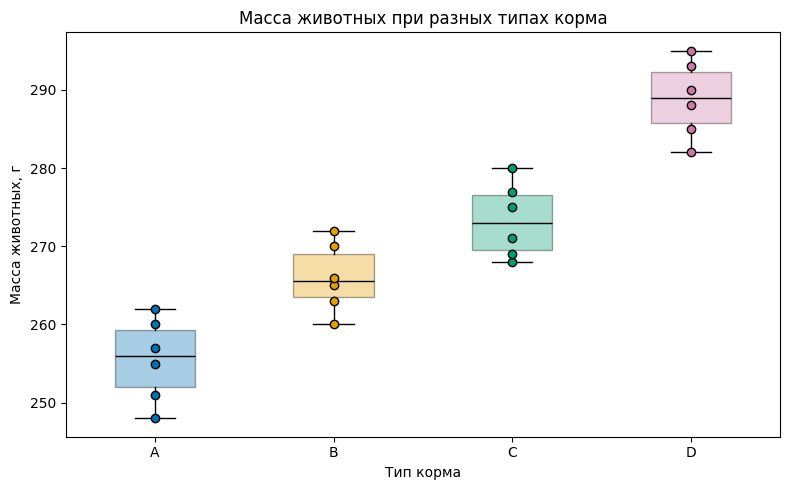

In [8]:
# Сравниваем массу животных при разных типах корма и показываем все наблюдения.
plt.figure(figsize=(8, 5))
boxes = plt.boxplot(groups, patch_artist=True, medianprops={"color": "black"})
for box, color in zip(boxes["boxes"], colors):
    box.set_facecolor(color)
    box.set_alpha(0.35)
for i, (group, color) in enumerate(zip(groups, colors), start=1):
    plt.scatter([i] * len(group), group, color=color, edgecolors="black", zorder=3)
plt.xticks([1, 2, 3, 4], labels)
plt.xlabel("Тип корма")
plt.ylabel("Масса животных, г")
plt.title("Масса животных при разных типах корма")
plt.tight_layout()
plt.show()

In [9]:
alpha = 0.05

# Проверяем нормальность массы в каждой группе перед сравнением средних.
for label, group in zip(labels, groups):
    _, p_shapiro = shapiro(group)
    print(f"p-value критерия Шапиро–Уилка, корм {label}: {p_shapiro:.4f}")

# Проверяем, одинаков ли разброс массы животных во всех четырех группах.
_, p_levene = levene(A, B, C, D, center="median")
print(f"p-value критерия Левена: {p_levene:.4f}")

p-value критерия Шапиро–Уилка, корм A: 0.8799
p-value критерия Шапиро–Уилка, корм B: 0.9168
p-value критерия Шапиро–Уилка, корм C: 0.6488
p-value критерия Шапиро–Уилка, корм D: 0.9415
p-value критерия Левена: 0.9417


Так как p-value критерия Шапиро–Уилка во всех группах больше 0,05, то нет оснований отвергать гипотезу о нормальности.
p-value критерия Левена = 0,9417 тоже больше 0,05, поэтому нет оснований отвергать равенство дисперсий. 
Для сравнения средних используем однофакторный ANOVA.
При этом в каждой группе всего 6 наблюдений, поэтому проверка Шапиро–Уилка не доказывает нормальность распределений.

In [10]:
# Проверяем, различается ли средняя масса животных при разных типах корма.
# H0: μ_A = μ_B = μ_C = μ_D; H1: не все средние равны. Уровень значимости — 0,05.
f_stat, p_value = f_oneway(A, B, C, D)
print(f"F-статистика ANOVA: {f_stat:.4f}")
print(f"p-value ANOVA: {p_value:.10f}")

F-статистика ANOVA: 49.9246
p-value ANOVA: 0.0000000018


Так как p-value ANOVA = 0,0000000018 меньше 0,05, то отвергаем гипотезу о равенстве всех средних.
Используем Tukey HSD, чтобы понять, между какими типами корма есть различия, с учетом множественных сравнений.

In [11]:
# Сравниваем все пары кормов, чтобы определить, какие из них дают разную среднюю массу.
weights = np.concatenate(groups)
feed_labels = np.repeat(labels, [len(group) for group in groups])
tukey_result = pairwise_tukeyhsd(weights, feed_labels, alpha=0.05)
print(tukey_result)

# Средние по группам показывают, у какого корма наблюдается наибольшая масса животных.
for label, group in zip(labels, groups):
    print(f"Средняя масса, корм {label}: {np.mean(group):.2f} г")

Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
     A      B     10.5 0.0064  2.6524 18.3476   True
     A      C  17.8333    0.0  9.9858 25.6809   True
     A      D  33.3333    0.0 25.4858 41.1809   True
     B      C   7.3333 0.0723 -0.5142 15.1809  False
     B      D  22.8333    0.0 14.9858 30.6809   True
     C      D     15.5 0.0001  7.6524 23.3476   True
----------------------------------------------------
Средняя масса, корм A: 255.50 г
Средняя масса, корм B: 266.00 г
Средняя масса, корм C: 273.33 г
Средняя масса, корм D: 288.83 г


**Вывод:** По результатам Tukey HSD корм D наиболее эффективен по средней массе животных — **288,83 г**. По сравнению с остальными кормами:

- **A:** средняя масса 255,50 г; преимущество D — 33,33 г, 95% ДИ разности — [25,49; 41,18] г.
- **B:** средняя масса 266,00 г; преимущество D — 22,83 г, 95% ДИ разности — [14,99; 30,68] г.
- **C:** средняя масса 273,33 г; преимущество D — 15,50 г, 95% ДИ разности — [7,65; 23,35] г.

Все три интервала не содержат ноль, поэтому различия статистически значимы. Значимые различия обнаружены между всеми парами кормов, кроме B и C: для этой пары интервал [−0,51; 15,18] г содержит ноль, а p-value = 0,0723 больше 0,05.

### Задание 6. A/B-тест по конверсии

Проводится A/B-тест на лендинге. В контрольной группе из 1000 пользователей конверсий 85, в тестовой группе из 1000 пользователей конверсий 120.

**Что сделать:**
- постройте 95% доверительные интервалы Уилсона для конверсии каждой группы;
- проверьте, значимо ли различаются конверсии (критерий хи-квадрат на таблице 2x2 или z-тест для двух долей) при $\alpha = 0.05$;
- постройте бутстрэп-интервал для разности конверсий (тест минус контроль);
- сделайте вывод, стоит ли выкатывать тестовый вариант.

**Выведите на экран:** границы интервалов Уилсона по группам, статистику и p-value выбранного теста, границы бутстрэп-интервала для разности и точечную разность конверсий.

In [12]:
conv_c, n_c = 85, 1000     # контроль
conv_v, n_v = 120, 1000    # тест

alpha = 0.05

# Сравниваем долю пользователей с конверсией; положительная разность — в пользу теста.
p_c = conv_c / n_c
p_v = conv_v / n_v
conversion_diff = p_v - p_c
print(f"Конверсия контроля: {p_c:.2%}")
print(f"Конверсия теста: {p_v:.2%}")
print(f"Разность тест − контроль: {conversion_diff * 100:.2f} п.п.")

Конверсия контроля: 8.50%
Конверсия теста: 12.00%
Разность тест − контроль: 3.50 п.п.


In [13]:
# Интервалы Уилсона показывают неопределенность оценки конверсии в каждой группе.
ci_c = proportion_confint(conv_c, n_c, alpha=alpha, method="wilson")
ci_v = proportion_confint(conv_v, n_v, alpha=alpha, method="wilson")
print(f"95% интервал Уилсона, контроль: [{ci_c[0]:.2%}, {ci_c[1]:.2%}]")
print(f"95% интервал Уилсона, тест: [{ci_v[0]:.2%}, {ci_v[1]:.2%}]")

95% интервал Уилсона, контроль: [6.93%, 10.39%]
95% интервал Уилсона, тест: [10.13%, 14.16%]


In [14]:
# Проверяем различие конверсий в обе стороны: H0: p_тест = p_контроль, H1: p_тест <> p_контроль.
z_stat, p_value = proportions_ztest(
    [conv_v, conv_c], [n_v, n_c], value=0, alternative="two-sided"
)
print(f"z-статистика: {z_stat:.4f}, p-value: {p_value:.6f}")

z-статистика: 2.5803, p-value: 0.009871


Так как p-value = 0,009871 меньше 0,05, то отвергаем гипотезу о равенстве конверсий.
Конверсия теста выше на 3,50 п.п. Построим бутстрэп-интервал, чтобы оценить неопределенность этой разности.

In [15]:
np.random.seed(42)

# Каждый пользователь либо совершил конверсию (1), либо нет (0).
control = np.array([1] * conv_c + [0] * (n_c - conv_c))
variant = np.array([1] * conv_v + [0] * (n_v - conv_v))

# Повторные выборки внутри каждой группы показывают изменчивость разности конверсий.
bootstrap_diffs = []
for _ in range(10000):
    sample_c = np.random.choice(control, size=n_c, replace=True)
    sample_v = np.random.choice(variant, size=n_v, replace=True)
    bootstrap_diffs.append(np.mean(sample_v) - np.mean(sample_c))

# Центральные 95% бутстрэп-разностей задают процентильный доверительный интервал.
ci_lower, ci_upper = np.percentile(bootstrap_diffs, [2.5, 97.5])
print(f"Разность тест − контроль: {conversion_diff * 100:.2f} п.п.")
print(f"95% бутстрэп-интервал: [{ci_lower * 100:.2f}, {ci_upper * 100:.2f}] п.п.")

Разность тест − контроль: 3.50 п.п.
95% бутстрэп-интервал: [0.80, 6.20] п.п.


**Вывод:** Так как 95% бутстрэп-интервал [0,80; 6,20] п.п. не содержит ноль и целиком лежит выше него, то делаем вывод, что конверсия тестового варианта статистически значимо выше.
Конверсия выросла с 8,5% до 12,0%, то есть на 3,5 п.п., поэтому по результатам анализа конверсии рекомендуется выкатить тестовый вариант.